# 06 决策树

本篇对应课程目录 `06_决策树`，依据教师笔记 `02-笔记/决策树.md` 整理，覆盖 ID3、C4.5、CART、泰坦尼克号生存预测、回归树和剪枝。第 05 篇学习的是用一组参数计算概率，本篇学习如何从数据中找出一连串判断条件。

资料：[机器学习课程网盘](https://pan.baidu.com/s/1NmWli9KoAeYtlpXTzhw-Jg?pwd=1234)，提取码 `1234`。

本轮已读取教师 Markdown 和 12 张课程配图。课程 `day06.zip` 未取得，因此泰坦尼克案例是依据讲义补写的实现，需要你提供实际 CSV；本篇不报告它的真实数据成绩。Iris 分类、课程十点回归和乳腺癌数据剪枝是已运行验证的示例，其中内置数据练习明确标为补充。

延续前面的笔记格式：全部为 Markdown 单元，Python 代码放在代码块中，复制到代码单元或脚本后运行。全部 15 张图片嵌入本 Notebook 附件，无独立图片文件依赖。

## 学习路线

| 阶段 | 要回答的问题 | 关键知识 |
| --- | --- | --- |
| 理解决策树 | 一个样本怎样沿条件得到结果？ | 根、内部节点、分支、叶子 |
| ID3 | 问哪个问题能减少最多不确定性？ | 熵、条件熵、信息增益 |
| C4.5 | 怎样缓解唯一 ID 被优先选择？ | 分裂信息、信息增益率 |
| CART 分类 | 哪个二分让类别更纯？ | Gini、类别集合、数值阈值 |
| 分类实战 | 如何预处理、训练、画树和评估？ | Pipeline、one-hot、分类指标 |
| CART 回归 | 哪个二分让两侧平方误差最小？ | 均值、SSE、分段常数 |
| 剪枝 | 怎样控制树的复杂度？ | 预剪枝、后剪枝、`ccp_alpha` |

本篇公式统一使用 $\log_2$，熵的单位为 bit。先学会手算，再观察 API 输出，避免只记住参数名称。

## 1. 决策树：从根节点走到叶节点

决策树是一种监督学习模型。内部节点判断一个特征，分支表示判断结果，叶节点给出最终预测。分类树输出类别或类别概率，回归树输出数值。

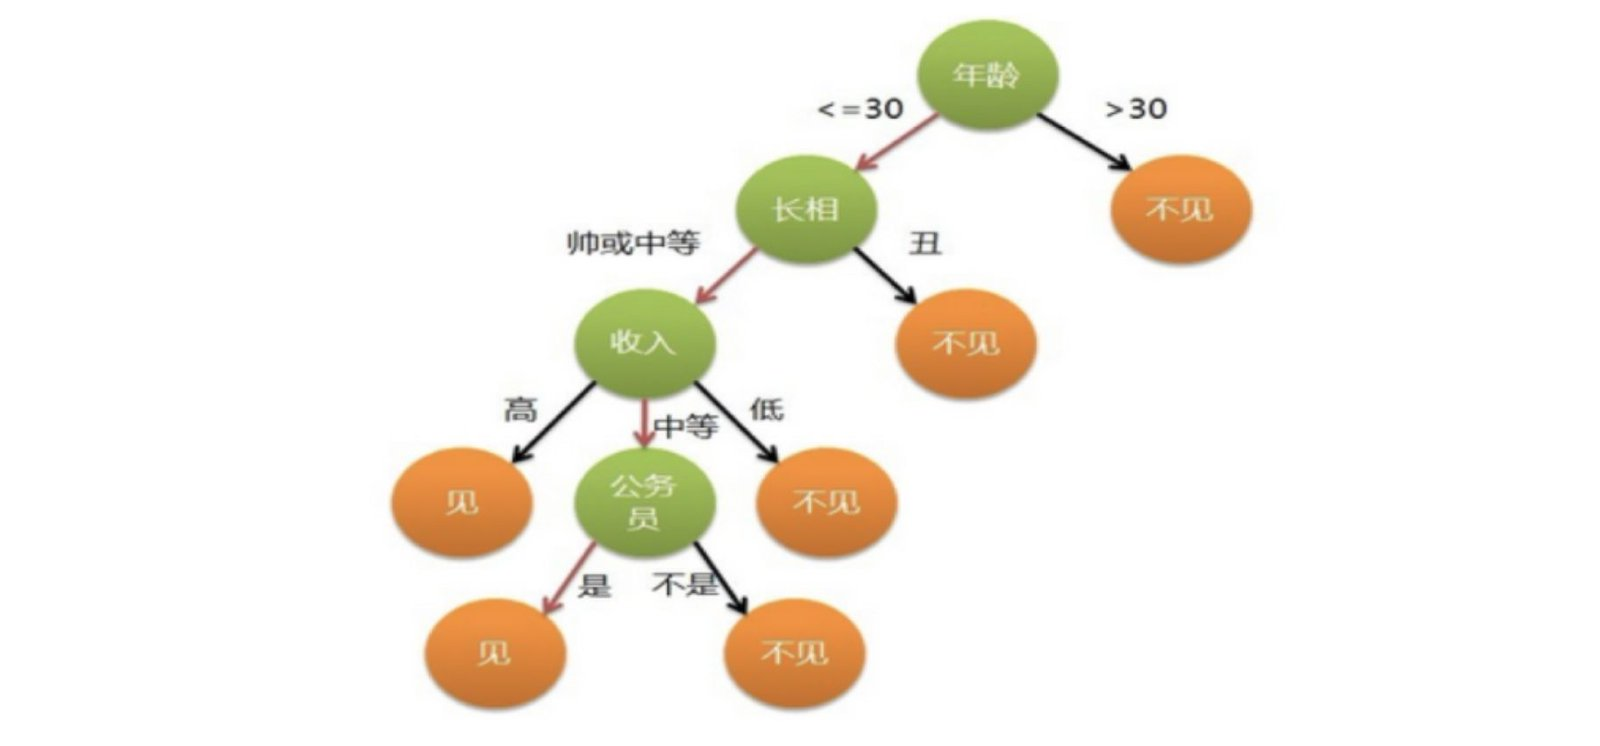

*原课用相亲问题解释 if/else。图里的规则用于说明结构；机器学习训练的核心，是从带标签样本中学习这些条件。*

例如分类规则可以是：先判断“花瓣宽度是否不超过 0.8”，满足就预测为某类，否则继续判断花瓣长度。预测一个新样本只需沿一条路径向下走，不需要遍历全部叶子。

- **根节点**：整棵树的入口，包含当前训练集全部样本。
- **内部节点**：继续分裂的节点，带有特征判断条件。
- **分支**：满足某个条件的样本去向。
- **叶节点**：停止分裂的节点；分类通常取多数类，平方误差回归取均值。

本文按照 sklearn 的约定：根节点深度为 0，走过一条边深度增加 1。

### 1.1 训练时做什么

训练每个节点时，都要在“候选特征＋候选切分”中寻找最佳方案，然后对子集递归重复。数值特征通常判断 $x_j\le s$；原生离散特征可以按取值分支，也可以将取值集合二分。

一个基本流程是：

1. 计算当前节点的不纯度，检查是否已经全部同类。
2. 枚举允许的特征与切分方式。
3. 按信息增益、增益率、Gini 降低或平方误差降低评分。
4. 采用最佳合法切分，对子节点继续训练。
5. 满足停止条件时生成叶子；需要时进一步剪枝。

常见停止条件包括节点已经纯净、没有可用特征或有效切分、达到深度限制、样本太少、改进幅度不足。多数类并列时需要确定的处理规则；遇到训练时未见过的类别，也要提前约定预测行为。

这个过程是**局部贪心搜索**：每次选择当前最好的切分，不保证得到全局最优的整棵树。连续特征在不同节点可以重复使用。

## 2. 信息熵：衡量类别有多混杂

设节点数据为 $D$，有 $K$ 个类别，第 $k$ 类的比例是 $p_k$：

$$H(D)=-\sum_{k=1}^{K}p_k\log_2p_k$$

类别越均匀，熵越大；全部属于同一类时熵为 0。固定 $K$ 类时，最大熵是 $\log_2K$，并非所有分类任务的熵都不超过 1。

约定 $0\log_2 0=0$，来自极限；实际计算时跳过比例为 0 的项。

| 类别比例 | 用 $\log_2$ 计算 | 用自然对数 $\ln$ 计算 | 含义 |
| --- | ---: | ---: | --- |
| $(1/3,1/3,1/3)$ | 1.584963 | 1.098612 | 三类完全均匀 |
| $(0.1,0.2,0.7)$ | 1.156780 | 0.801819 | 一类占多数 |
| $(1,0,0)$ | 0 | 0 | 纯节点 |

教师笔记开头的 `1.0986`、`0.8018` 使用自然对数，后面的信息增益手算使用 $\log_2$。本篇统一对数底数；同一比较中保持底数一致，改变底数只会按同一比例缩放熵和信息增益。

### 2.1 用标签计算熵与特征评分

下面的函数针对**已经给定标签的离散特征**。它不会自动搜索连续阈值；连续特征要先构造候选切分。

```python
from collections import Counter
from math import log2

def entropy(labels):
    """根据类别标签计算熵，单位 bit。"""
    if len(labels) == 0:
        return 0.0
    counts = Counter(labels)
    n = len(labels)
    return -sum((c / n) * log2(c / n) for c in counts.values())

def feature_metrics(labels, values):
    """离散特征的条件熵、信息增益、分裂信息和增益率。"""
    if len(labels) != len(values) or len(labels) == 0:
        raise ValueError("标签与特征必须等长且非空")
    groups = {}
    for value, label in zip(values, labels):
        groups.setdefault(value, []).append(label)
    n = len(labels)
    conditional = sum(len(g) / n * entropy(g) for g in groups.values())
    gain = entropy(labels) - conditional
    split_info = entropy(values)
    ratio = gain / split_info if split_info > 0 else None
    return conditional, gain, split_info, ratio

print(round(entropy(["A", "B", "C"]), 6))  # 1.584963
print(round(entropy(["A"] + ["B"] * 2 + ["C"] * 7), 6))
print(entropy(["A"] * 10))  # 0
```

输出约为 `1.584963、1.156780、0`。浮点数显示 `-0.0` 与 `0.0` 数值相同。

条件熵中的权重来自子集大小。三个子节点包含 8、1、1 个样本时，权重是 `0.8、0.1、0.1`，不能简单平均三个熵。

## 3. ID3：选择信息增益最大的特征

离散特征 $A$ 把 $D$ 分成若干子集 $D_v$。分裂后的平均不确定性为：

$$H(D\mid A)=\sum_{v}\frac{|D_v|}{|D|}H(D_v)$$

信息增益衡量一次分裂减少了多少不确定性：

$$\operatorname{Gain}(D,A)=H(D)-H(D\mid A)$$

ID3 在当前节点选择信息增益最大的特征。增益比较必须针对同一个父节点；不同节点上的数值不能直接当成全局特征重要性比较。

课程的六样本例子：

| 样本 | 特征 a | 标签 |
| ---: | --- | --- |
| 1 | α | A |
| 2 | α | A |
| 3 | β | B |
| 4 | α | A |
| 5 | β | B |
| 6 | α | B |

父节点有 3 个 A、3 个 B，$H(D)=1$。按 a 分裂：α 子集为 `AAAB`，β 子集为 `BB`。

$$H(D\mid a)=\frac46\left(-\frac34\log_2\frac34-\frac14\log_2\frac14\right)+\frac26\times0=0.540852$$

$$\operatorname{Gain}(D,a)=1-0.540852=0.459148$$

分裂后 β 子集已经纯净，α 子集仍混杂。如果还有其他特征，可以继续在 α 子集上计算；没有特征可用时，预测多数类 A。

### 3.1 ID3 的递归构建与局限

原始 ID3 主要面向离散属性，每个特征取值通常产生一个分支。选中特征后，子树继续使用剩余离散特征。

```text
build(D, features):
    如果 D 全部同类：返回该类叶子
    如果没有候选特征或没有有效增益：返回 D 的多数类叶子
    A = 当前节点信息增益最大的特征
    对 A 的每个取值 v：
        对 D_v 使用剩余特征递归建树
    返回以 A 为判断条件的节点
```

一个重要问题是**信息增益偏爱取值较多的特征**。若某列为每行唯一的 ID，分裂后每个子集仅一行，子集熵全为 0，增益达到父节点熵。它看似完美区分训练样本，却无法给新的 ID 提供可泛化的规律。

ID、预测时拿不到的字段、预测事件发生后才产生的字段，应依据业务含义删除，不能只依赖算法评分来排除。

## 4. 论坛流失：性别与活跃度的手算

课程有 15 条样本，约定 `1=流失、0=未流失`：5 条流失，10 条未流失。

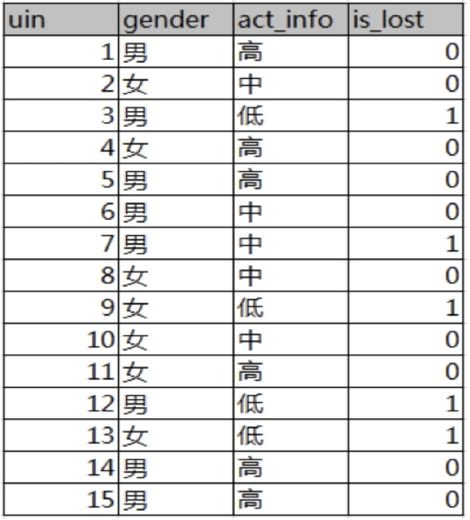

*原课数据表。完整数据也写在下一单元的代码中，可复制复算。*

父节点熵：

$$H(D)=-\frac5{15}\log_2\frac5{15}-\frac{10}{15}\log_2\frac{10}{15}=0.918296$$

| 特征组 | 样本数 | 流失数 | 未流失数 | 组内熵 |
| --- | ---: | ---: | ---: | ---: |
| 男 | 8 | 3 | 5 | 0.954434 |
| 女 | 7 | 2 | 5 | 0.863121 |
| 高活跃 | 6 | 0 | 6 | 0 |
| 中活跃 | 5 | 1 | 4 | 0.721928 |
| 低活跃 | 4 | 4 | 0 | 0 |

性别的条件熵与增益：

$$H(D\mid\text{性别})=\frac8{15}\times0.954434+\frac7{15}\times0.863121=0.911821$$

$$\operatorname{Gain}(D,\text{性别})=0.918296-0.911821=0.006475$$

活跃度的条件熵与增益：

$$H(D\mid\text{活跃度})=\frac6{15}\times0+\frac5{15}\times0.721928+\frac4{15}\times0=0.240643$$

$$\operatorname{Gain}(D,\text{活跃度})=0.918296-0.240643=0.677653$$

本节点应先按活跃度分裂。这个结果说明活跃度在当前样本中区分类别的能力更强，不能直接解释为“活跃度是流失的原因”。

### 4.1 用代码复算，再观察子节点

```python
import pandas as pd

# 先运行上一节的 entropy 和 feature_metrics；0=未流失，1=流失
forum = pd.DataFrame([
    ["男", "高", 0], ["女", "中", 0], ["男", "低", 1],
    ["女", "高", 0], ["男", "高", 0], ["男", "中", 0],
    ["男", "中", 1], ["女", "中", 0], ["女", "低", 1],
    ["女", "中", 0], ["女", "高", 0], ["男", "低", 1],
    ["女", "低", 1], ["男", "高", 0], ["男", "高", 0],
], columns=["性别", "活跃度", "流失"])
print("父节点熵：", round(entropy(forum["流失"].tolist()), 6))
for feature in ["性别", "活跃度"]:
    conditional, gain, _, _ = feature_metrics(
        forum["流失"].tolist(), forum[feature].tolist())
    print(feature, "条件熵=", round(conditional, 6),
          "信息增益=", round(gain, 6))
```

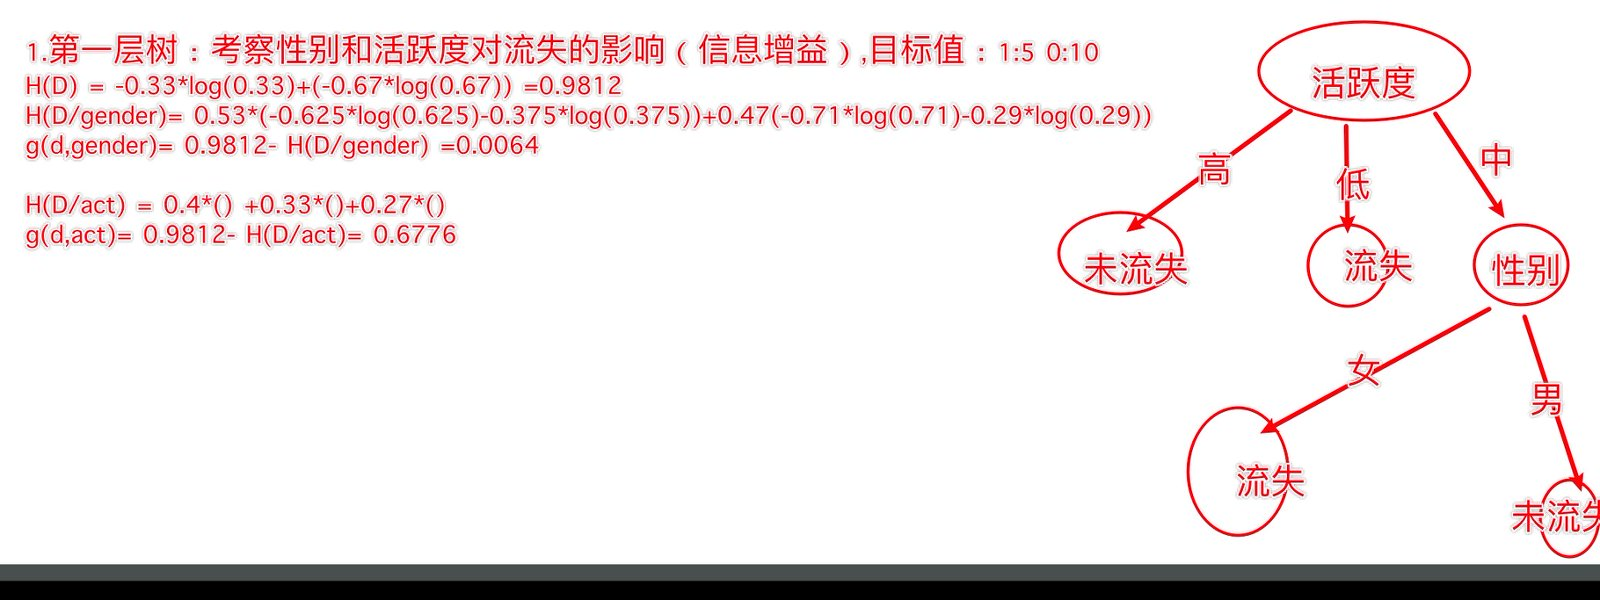

*原课板书包含按活跃度生成的根节点。高、低活跃子集已经纯净；中活跃还有一条流失样本，需要继续判断或在停止时采用多数类。*

如果在中活跃子集继续比较性别，应重新使用这 5 条样本计算，不能沿用根节点的 `0.006475`。

## 5. C4.5：信息增益率

C4.5 用分裂信息对信息增益作归一化：

$$\operatorname{SplitInfo}(D,A)=-\sum_v\frac{|D_v|}{|D|}\log_2\frac{|D_v|}{|D|}$$

$$\operatorname{GainRatio}(D,A)=\frac{\operatorname{Gain}(D,A)}{\operatorname{SplitInfo}(D,A)}$$

分裂信息衡量**样本被分到各分支的分散程度**；它计算的是分支大小比例，不是分支内标签比例。分支越均匀通常越大。取值数和分布共同决定它，不能只看取值数。

在六样本数据中增加每行唯一的 b：

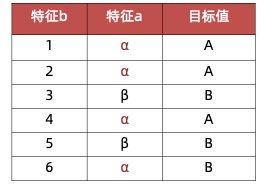

| 特征 | 信息增益 | SplitInfo | 增益率 |
| --- | ---: | ---: | ---: |
| a：α 4 行，β 2 行 | 0.459148 | 0.918296 | 0.500000 |
| b：6 个唯一值 | 1.000000 | 2.584963 | 0.386853 |

信息增益选择 b，增益率在本例中选择 a。唯一 ID 的增益被分成 6 个分支的代价稀释了。

### 5.1 复算和使用边界

```python
# 先运行上一节的 entropy 和 feature_metrics
y = ["A", "A", "B", "A", "B", "B"]
a = ["α", "α", "β", "α", "β", "α"]
b = [1, 2, 3, 4, 5, 6]  # 每行唯一的标识
for name, values in [("a", a), ("b（唯一ID）", b)]:
    conditional, gain, split_info, ratio = feature_metrics(y, values)
    print(name, {"条件熵": round(conditional, 6),
                 "信息增益": round(gain, 6),
                 "SplitInfo": round(split_info, 6),
                 "信息增益率": round(ratio, 6)})
```

常量特征只有一个分支，`SplitInfo=0`，不能除以 0；上面的函数用 `None` 表示没有可用增益率。

增益率也可能偏向分裂信息极小的特征。典型 C4.5 会先筛选信息增益达到一定水平的候选，再比较增益率；不要把完整算法简化成“无条件选最大比值”。C4.5 还包含连续属性、缺失值处理和剪枝等机制，本篇重点是增益率思想。

将 sklearn 的 `criterion` 改成 `"entropy"` 并不会自动获得 C4.5：评分中并没有除以 `SplitInfo`。

## 6. CART 分类树：找最好的二分

CART 是 Classification And Regression Trees，可用于分类和回归。它的树结构是二叉树，每次只生成两个子节点。

分类常用 Gini 不纯度：

$$\operatorname{Gini}(D)=1-\sum_{k=1}^{K}p_k^2$$

纯节点的 Gini 为 0。二分类均匀节点的 Gini 为 0.5；$K$ 类均匀节点的最大值为 $1-1/K$。

候选切分把 D 分成左右两部分，评价的是**子节点加权 Gini**：

$$\operatorname{Gini}_{\mathrm{split}}=\frac{|D_L|}{|D|}\operatorname{Gini}(D_L)+\frac{|D_R|}{|D|}\operatorname{Gini}(D_R)$$

在同一个父节点，最小化这个量等价于最大化不纯度降低：

$$\Delta\operatorname{Gini}=\operatorname{Gini}(D)-\operatorname{Gini}_{\mathrm{split}}$$

Gini 小表示类别更集中。这里是分类不纯度指标，不是经济学中用于衡量收入分配的 Gini 系数。

### 6.1 课程数据：是否拖欠贷款

10 条样本含有 `house`、`marital`、`income` 特征，目标是 `default`。下文统一大小写；约定 `1=拖欠、0=未拖欠`。

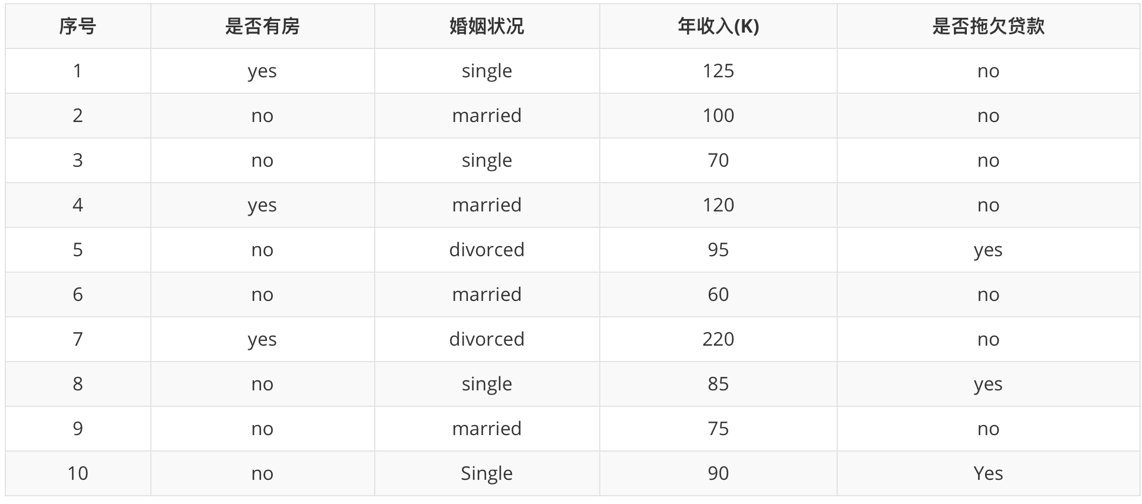

| ID | 有房 house | 婚姻 marital | 收入 income | 拖欠 default |
| ---: | --- | --- | ---: | ---: |
| 1 | yes | single | 125 | 0 |
| 2 | no | married | 100 | 0 |
| 3 | no | single | 70 | 0 |
| 4 | yes | married | 120 | 0 |
| 5 | no | divorced | 95 | 1 |
| 6 | no | married | 60 | 0 |
| 7 | yes | divorced | 220 | 0 |
| 8 | no | single | 85 | 1 |
| 9 | no | married | 75 | 0 |
| 10 | no | single | 90 | 1 |

父节点有 7 条未拖欠、3 条拖欠：

$$\operatorname{Gini}(D)=1-0.7^2-0.3^2=0.42$$

这里的收入沿用原表数值，手算只关心相对顺序和阈值，不额外推断其货币单位。

### 6.2 离散特征：二分的是类别集合

有房特征只有两类，`yes | no`：有房的 3 条全部未拖欠；无房的 7 条中 4 条未拖欠、3 条拖欠。

$$\operatorname{Gini}_{\mathrm{house}}=\frac3{10}\times0+\frac7{10}\left[1-\left(\frac47\right)^2-\left(\frac37\right)^2\right]=0.342857$$

婚姻有 3 类，但 CART 不直接生成 3 条分支，需要比较类别集合的二分：

| 候选二分 | 加权 Gini |
| --- | ---: |
| `{married}` 与 `{single, divorced}` | **0.300000** |
| `{single}` 与 `{married, divorced}` | 0.366667 |
| `{divorced}` 与 `{single, married}` | 0.400000 |

以 married 二分时：左侧 4 条全未拖欠，右侧 6 条两类各 3 条，所以：

$$\frac4{10}\times0+\frac6{10}\left[1-\left(\frac36\right)^2-\left(\frac36\right)^2\right]=0.3$$

“婚姻特征的最佳 Gini 是 0.3”意味着已经搜索过它的候选二分。类别数更多时，只枚举“一个类别与其余类别”未必覆盖全部可能的类别集合二分。

sklearn 的常用决策树接口需要数值输入。one-hot 后搜索的是编码列的二分，并不等同于原生类别集合的完整搜索。

### 6.3 连续特征：排序后搜索阈值

将收入排序为 `60、70、75、85、90、95、100、120、125、220`，用相邻**不同值**的中点作为候选：

$$65,\ 72.5,\ 80,\ 87.5,\ 92.5,\ 97.5,\ 110,\ 122.5,\ 172.5$$

同一阈值的规则固定为 `income ≤ t` 和 `income > t`，确保每个样本只归入一侧。

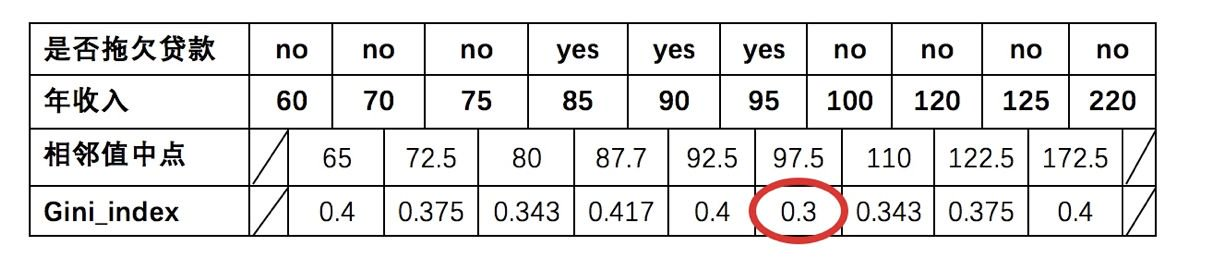

| 收入阈值 | 左右加权 Gini |
| --- | --- |
| 65 | 0.400000 |
| 72.5 | 0.375000 |
| 80 | 0.342857 |
| 87.5 | 0.416667 |
| 92.5 | 0.400000 |
| 97.5 | 0.300000 |
| 110 | 0.342857 |
| 122.5 | 0.375000 |
| 172.5 | 0.400000 |

最优收入阈值是 `97.5`：左侧 6 条中 3 条拖欠、3 条未拖欠，右侧 4 条全未拖欠，加权 Gini 为 0.3。阈值必须在当前节点的训练样本内搜索，不能用测试样本帮忙确定。

### 6.4 用完整数据复算 Gini

下面代码复算有房、婚姻、收入的候选切分。`gini()` 计算一个节点的不纯度，`split_gini()` 计算左右节点加权后的不纯度，两者的含义不同。

```python
from collections import Counter
import numpy as np
import pandas as pd

def gini(labels):
    if len(labels) == 0:
        return 0.0
    n = len(labels)
    return 1.0 - sum((c / n) ** 2 for c in Counter(labels).values())

def split_gini(labels, left_mask):
    labels = np.asarray(labels)
    left_mask = np.asarray(left_mask, dtype=bool)
    if left_mask.sum() == 0 or left_mask.sum() == len(labels):
        return float("inf")  # 空子集不是合法切分
    return (left_mask.mean() * gini(labels[left_mask])
            + (~left_mask).mean() * gini(labels[~left_mask]))

loan_cart = pd.DataFrame([
    ["yes", "single", 125, 0], ["no", "married", 100, 0],
    ["no", "single", 70, 0], ["yes", "married", 120, 0],
    ["no", "divorced", 95, 1], ["no", "married", 60, 0],
    ["yes", "divorced", 220, 0], ["no", "single", 85, 1],
    ["no", "married", 75, 0], ["no", "single", 90, 1],
], columns=["house", "marital", "income", "default"])
y_cart = loan_cart["default"].to_numpy()
print("父节点Gini：", gini(y_cart))
print("有房二分：", split_gini(y_cart, loan_cart["house"].eq("yes")))
for status in ["married", "single", "divorced"]:
    print(status, split_gini(y_cart, loan_cart["marital"].eq(status)))

unique_income = np.sort(loan_cart["income"].unique())
thresholds = (unique_income[:-1] + unique_income[1:]) / 2
income_scores = pd.DataFrame([
    {"threshold": float(t), "weighted_gini": split_gini(
        y_cart, loan_cart["income"].le(t))}
    for t in thresholds
])
print(income_scores.round(6).to_string(index=False))
print("收入最佳：", income_scores.loc[income_scores["weighted_gini"].idxmin()])
```

对于重复数值，先取唯一值再计算中点；不能把相等数值拆到两侧。

### 6.5 根节点确定后继续递归

最佳婚姻二分和最佳收入阈值的加权 Gini 都是 0.3。本例选择“是否 married”为根：

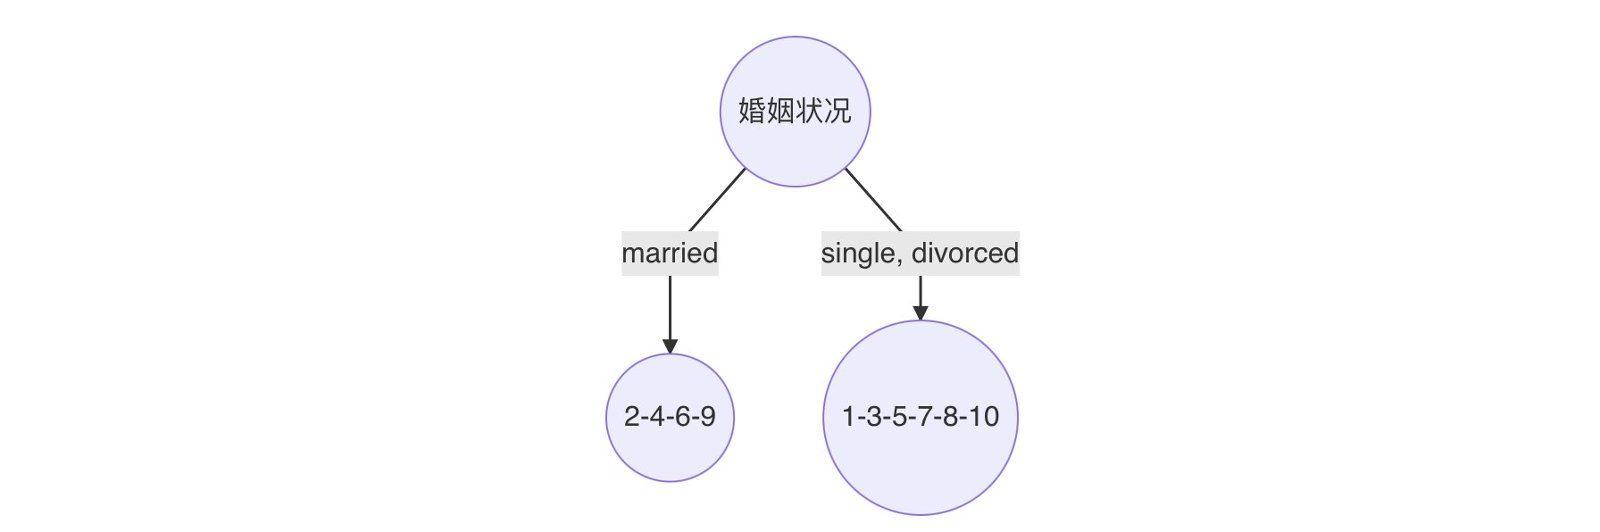

*married 分支已经纯净；single/divorced 分支仍需继续搜索。图只是当前生长阶段，不是最终完整分类规则。*

同分时可使用固定优先级或实现规定的规则。sklearn 中随机排列特征可能影响同分切分，固定 `random_state` 有助于复现；不是任何同分都必须手动随机选择。

下一步只在未婚/离异的 6 条样本中计算候选切分。每个子节点都有自己的比例、不纯度和最佳阈值。

## 7. ID3、C4.5、CART 对照

| 项目 | ID3 | C4.5 | CART |
| --- | --- | --- | --- |
| 本篇核心准则 | 信息增益 | 信息增益率 | 分类 Gini；回归平方误差 |
| 树结构 | 离散属性通常多叉 | 离散属性可多叉，连续属性常二分 | 二叉 |
| 连续属性 | 原始算法主要面向离散属性 | 支持阈值划分 | 支持阈值划分 |
| 常见问题 | 偏爱取值多的属性 | 增益率需结合候选筛选 | 大树易拟合噪声 |
| 能否直接做回归 | 本篇讨论分类 ID3 | 本篇讨论分类 C4.5 | 可以 |

**sklearn 的 `DecisionTreeClassifier` 使用 CART 风格的二叉树结构。**`criterion="gini"` 用 Gini，`criterion="entropy"` 用熵评估不纯度降低；新版本也支持 `"log_loss"`。选择 entropy 不会把结构变成 ID3 的多叉树，也不会变成 C4.5 的增益率。

熵与 Gini 都衡量类别混杂程度。它们可能选出相同切分，也可能不同；实际效果要通过训练之外的数据比较。

## 8. sklearn 分类树 API 与复杂度控制

```python
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    min_samples_split=2,
    min_samples_leaf=2,
    random_state=21,
)
```

| 参数 | 控制什么 | 学习时如何理解 |
| --- | --- | --- |
| `criterion` | 节点不纯度标准 | 分类可选 Gini 或熵等 |
| `max_depth` | 最大树深度 | 小值限制规则链长度；根深度为 0 |
| `min_samples_split` | 内部节点允许继续切分的最少样本数 | 满足条件后，仍需寻找合法切分 |
| `min_samples_leaf` | 每个新叶子至少有多少样本 | 候选切分的两侧都必须满足 |
| `max_leaf_nodes` | 最大叶子数量 | 直接限制模型包含多少个预测区域 |
| `min_impurity_decrease` | 全树加权的不纯度改进门槛 | 改进不足时拒绝切分 |
| `ccp_alpha` | 代价复杂度剪枝强度 | 0 表示无该项剪枝；越大通常越简单 |
| `class_weight` | 不同类别的训练权重 | 可用 `"balanced"`，需验证效果 |
| `random_state` | 随机过程复现 | 固定种子便于对照 |

`min_samples_leaf` 是**生长时拒绝不合法切分**，不是先生成小叶子再与兄弟节点一起剪掉。样本阈值也可使用比例形式，具体规则查安装版本文档。

不要把“深度常取 10～100”当成通用建议。小数据和简单任务可能只需要几层；限制太紧会欠拟合。

### 8.1 树不需要标准化，但仍需要准备输入

树的数值切分主要依赖数值顺序。标准化通常不会提供 KNN 或线性模型那样的必要帮助；为了方便可解释性，本篇不加 `StandardScaler`。

但这不等于可以原样投入任意表格：

- 字符串类别需要合适编码，常用训练集内 one-hot；随意编码成 0、1、2 会引入人为顺序。
- 缺失值要按版本、算法配置和任务处理，本篇显式使用训练集内填补器。
- 目标、ID、预测时不可获得的字段要删除。
- 样本权重、类别权重会改变训练中的有效比例；手算例子都使用等权样本。

切分时常见的全树加权改进为：

$$\frac{N_t}{N}\left[I_t-\frac{N_L}{N_t}I_L-\frac{N_R}{N_t}I_R\right]$$

$N$ 是整棵树训练样本数，$N_t$ 是当前节点样本数。权重配置下使用对应的加权样本量。树底部的一个小节点即使局部变纯，对全局的贡献也可能很小。

## 9. 补充实战：Iris 分类和画树

Iris 是 sklearn 内置数据，150 条样本、4 个数值特征、3 个类别；不需要从网络下载。用它检查“训练→预测→评估→画树”的完整流程。

本例按类别分层切分，固定 `random_state=21`，设置最大深度 3、叶子最少 2 条样本。代码中的参数是演示设置，未使用测试集调参。

```python
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, test_size=0.25, stratify=iris.target,
    random_state=21)
clf = DecisionTreeClassifier(
    criterion="gini", max_depth=3, min_samples_leaf=2, random_state=21)
clf.fit(X_train, y_train)
pred = clf.predict(X_test)
iris_result = {
    "train_size": len(y_train), "test_size": len(y_test),
    "accuracy": accuracy_score(y_test, pred),
    "macro_f1": f1_score(y_test, pred, average="macro"),
    "depth": clf.get_depth(), "leaves": clf.get_n_leaves(),
}
print(iris_result)
print(confusion_matrix(y_test, pred, labels=clf.classes_))
print(export_text(clf, feature_names=list(iris.feature_names)))

fig, ax = plt.subplots(figsize=(14, 7))
plot_tree(clf, feature_names=iris.feature_names,
          class_names=list(iris.target_names), filled=True,
          rounded=True, impurity=True, proportion=False, ax=ax,
          fontsize=10)
ax.set_title("Iris classification tree | training split only")
fig.tight_layout()
plt.show()
```

代码依赖 `numpy、matplotlib、scikit-learn`。本篇还使用 pandas。运行环境准备好这些包后，Iris、回归和剪枝示例都可以直接执行。

### 9.1 本轮实际结果

| 指标 | 实际值 |
| --- | --- |
| 训练 / 测试样本数 | 112 / 38 |
| 测试 accuracy | 0.947368 |
| 测试 macro-F1 | 0.948413 |
| 深度 / 叶子数 | 3 / 5 |

混淆矩阵按 `setosa、versicolor、virginica` 的顺序排列，行为真实类别，列为预测类别：

| 真实＼预测 | setosa | versicolor | virginica |
| --- | ---: | ---: | ---: |
| setosa | 12 | 0 | 0 |
| versicolor | 0 | 11 | 2 |
| virginica | 0 | 0 | 13 |

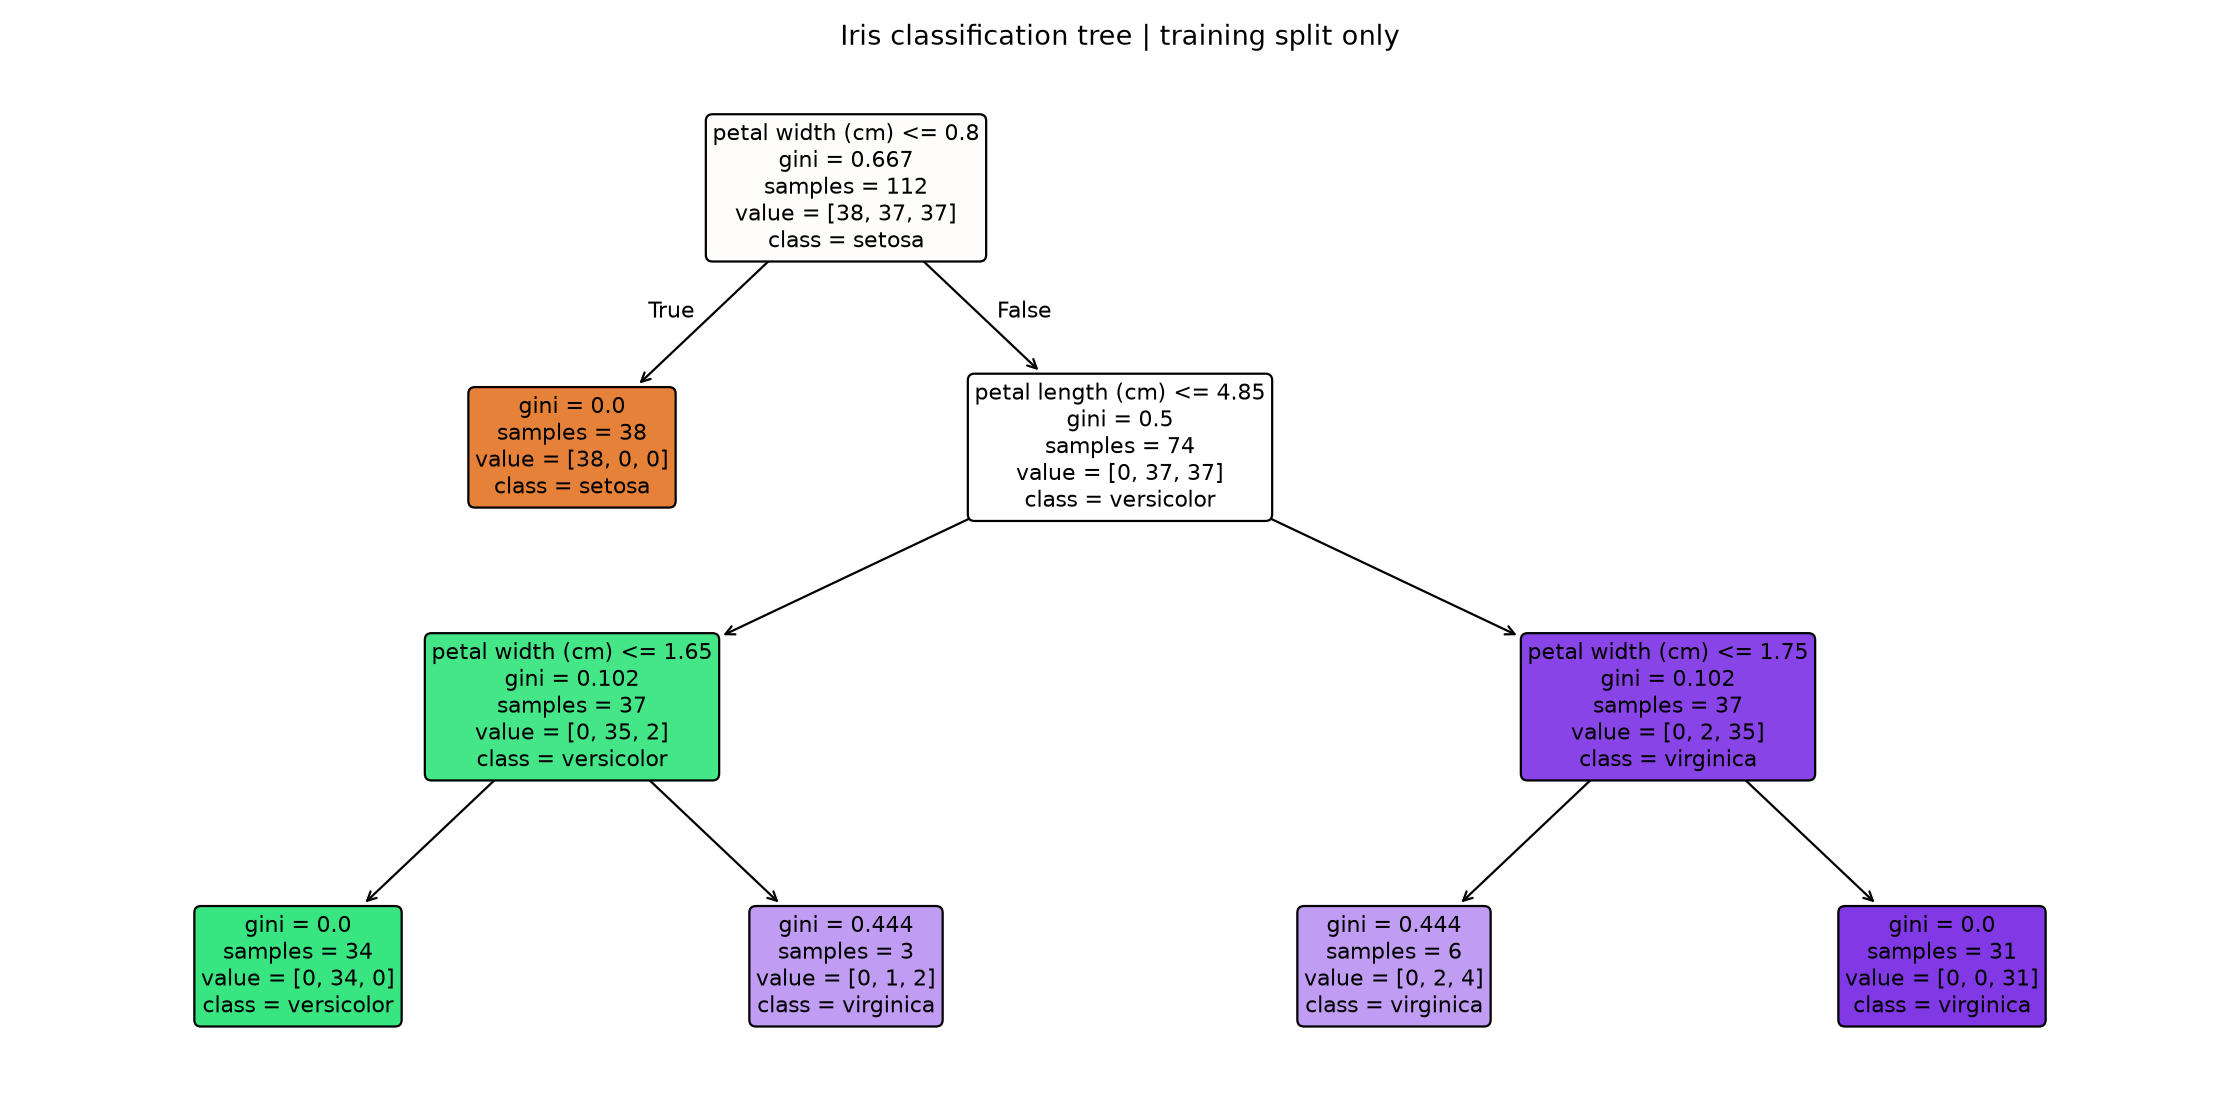

*补充绘图，来自上面实际训练的模型。测试集不参与节点条件学习；训练环境为 sklearn 1.9.1，跨版本的细节可能变化。*

图中的 `samples` 是到达节点的训练样本数；`gini` 是节点不纯度；`class` 是预测类别。`value` 反映各类分布，具体显示为数量还是归一化比例取决于 sklearn 版本和绘图设置，需结合 `classes_`、`samples` 判断。

### 9.2 如何读预测规则与概率

这棵树的根条件是花瓣宽度 `≤0.8 cm`。满足条件直接到 setosa 叶子；否则继续检查花瓣长度是否 `≤4.85 cm`。

分类树的 `predict_proba()` 来自对应叶子的训练类别分布，使用权重时来自加权分布。叶子只有一类时概率可为 1，这不代表现实世界中没有预测风险。小叶子的概率也常不稳定，需要独立评估，必要时做概率校准。

```python
# 接上一节 Iris 模型；先定位类别对应的概率列
print(clf.classes_)
print(clf.predict_proba(X_test[:3]))
print(clf.apply(X_test[:3]))  # 三个样本落入的叶子编号

importance = sorted(zip(iris.feature_names, clf.feature_importances_),
                    key=lambda item: item[1], reverse=True)
print(importance)
```

`feature_importances_` 按训练时不纯度降低汇总，可能偏向可用切分多的高基数特征。它说明当前模型利用了什么，不证明因果关系。可用验证集上的 permutation importance 补充检查；解释测试集结果后不要据此继续调模型。

## 10. 泰坦尼克号：明确目标与数据边界

课程案例希望根据乘客信息预测是否存活，目标为 `survived`，约定 `1=存活、0=未存活`。本篇选三个基线特征：

| 列 | 含义 | 处理方式 |
| --- | --- | --- |
| `pclass` | 舱位等级 | 数值填补；本例保留自然等级顺序 |
| `age` | 年龄 | 训练集的中位数填补 |
| `sex` | 性别类别 | 众数填补，再 one-hot |
| `survived` | 是否存活 | 目标，不能放入 X |

不同 Titanic 文件可能有大小写差异、不同字段或不同取值编码。下面只统一列名大小写，不猜测任意列的含义。先检查实际 CSV，再决定是否需要字段映射。

如有 `boat`、`body` 等救援或事故结果字段，它们可能在预测时不可获得，不能投入事前生存预测。固定特征白名单比直接把“除目标外全部列”投入模型更可靠。

课程教师 Markdown 的“案例实现”部分没有完整代码；下文为补写方案。由于课程 CSV 未取得，这里没有课程真数据的准确率或 AUC。

### 10.1 读取 CSV，验证标签和特征

```python
import numpy as np
import pandas as pd

def prepare_titanic(df):
    df = df.copy()
    df.columns = [str(c).strip().lower() for c in df.columns]
    if not df.columns.is_unique:
        raise ValueError("统一大小写后存在重复列名，请先检查文件")
    required = {"survived", "pclass", "age", "sex"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"缺少列：{sorted(missing)}；实际列：{list(df.columns)}")
    target = pd.to_numeric(df["survived"], errors="coerce")
    invalid = df["survived"].notna() & ~target.isin([0, 1])
    if invalid.any():
        raise ValueError("survived 必须是 0/1，其他标签请先明确映射")
    labeled = target.notna()  # 没有真实标签的行不参与监督训练
    X = df.loc[labeled, ["pclass", "age", "sex"]].copy()
    y = target.loc[labeled].astype(int)
    for col in ["pclass", "age"]:
        X[col] = pd.to_numeric(X[col], errors="coerce")
    sex = X["sex"].astype("string").str.strip().str.lower()
    X["sex"] = sex.astype(object).where(sex.notna() & sex.ne(""), np.nan)
    if y.nunique() != 2:
        raise ValueError("带标签数据需包含存活和未存活两类")
    return X, y

# 修改成你实际下载的 CSV 路径；运行前先查看列名和缺失值
df = pd.read_csv("data/titanic.csv")
print(df.shape, df.columns.tolist())
print(df.isna().sum())
X, y = prepare_titanic(df)
print(y.value_counts())
```

缺失目标无法提供监督标签，本例不拿这些行训练；应同时记录它们的数量。非空但不是 0/1 的标签会报错，避免把 `yes/no` 等任意编码悄悄当成 0。

`pd.to_numeric(..., errors="coerce")` 将无法解析的数值变为缺失；实际项目还需检查这些错误值的数量和来源。如果一列在训练集中全部缺失，应先处理数据问题，不能把填补器当成可靠信息来源。

### 10.2 Pipeline：让预处理只学习训练数据

```python
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.tree import DecisionTreeClassifier

# X、y 由上一节的 prepare_titanic 产生
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=21)
numeric = Pipeline([("fill", SimpleImputer(strategy="median"))])
categorical = Pipeline([
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocess = ColumnTransformer([
    ("num", numeric, ["pclass", "age"]),
    ("cat", categorical, ["sex"]),
])
pipe = Pipeline([
    ("preprocess", preprocess),
    ("model", DecisionTreeClassifier(
        max_depth=3, min_samples_leaf=5, random_state=21)),
])
pipe.fit(X_train, y_train)
pred = pipe.predict(X_test)
positive_column = list(pipe.named_steps["model"].classes_).index(1)
prob = pipe.predict_proba(X_test)[:, positive_column]
print(confusion_matrix(y_test, pred, labels=[0, 1]))
print(classification_report(y_test, pred, digits=4, zero_division=0))
print("ROC-AUC：", roc_auc_score(y_test, prob))
```

数值中位数、类别众数和 one-hot 类别表都由训练数据学习；测试集只执行转换。`handle_unknown="ignore"` 允许预测时出现训练未见过的类别，但该类别没有获得独立的训练分支。

这里使用一个固定参数基线，测试集在训练完成后报告一次。若要选 `max_depth`、`min_samples_leaf` 等参数，应在训练数据内部做交叉验证，或再留一个验证集，完成选择后才调用最后的测试评估。

ROC-AUC 用存活概率计算，不能使用 `pred` 的硬标签替代。分层切分要求两类有足够样本；不要把极小的几行数据当成有效评估集。

### 10.3 模型可视化和案例验收

```python
# 接上一节 Pipeline；特征名必须对应编码后的输入列
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

feature_names = pipe.named_steps["preprocess"].get_feature_names_out()
tree_model = pipe.named_steps["model"]
fig, ax = plt.subplots(figsize=(14, 7))
plot_tree(tree_model, feature_names=list(feature_names),
          class_names=[str(c) for c in tree_model.classes_],
          filled=True, rounded=True, ax=ax)
fig.tight_layout()
plt.show()
```

运行实际课程数据后，应检查：目标比例、年龄缺失比例、分层后的两类数量、混淆矩阵、分类报告、概率 AUC、树的深度和叶子数。模型若几乎全部预测一个类别，要检查数据、限制条件和评估指标。

本轮用**明确的合成表格**验证了缺失值填补、大小写统一、one-hot 和未知类别输入是否能通过 Pipeline；合成数据只验证程序结构，成绩不作为 Titanic 模型效果。

对包含亲属或同行群体的真实数据，随机切分还可能让相关乘客同时出现在训练和测试中。若目标是验证对新群体的泛化，应考虑按群体切分，并采用与实际使用场景相符的评估设计。

## 11. CART 回归树：用两侧平方误差选切分

分类树输出类别；回归树输出连续数值。以平方误差为准则时，一个叶子区域 R 的最优常数预测是其中目标值的均值：

$$c_R=\frac1{|R|}\sum_{i\in R}y_i$$

用特征 j、阈值 s 切成 $R_L(j,s)$ 和 $R_R(j,s)$，寻找：

$$\min_{j,s}\left[\sum_{i\in R_L(j,s)}(y_i-c_L)^2+\sum_{i\in R_R(j,s)}(y_i-c_R)^2\right]$$

这个和称为 SSE。不能只最小化左侧误差，也不能简单平均两个子集的 MSE；两侧样本数量不同，应按数量加权。固定父节点样本数时，最小化 SSE 等价于最小化加权子节点 MSE。

均值来自平方误差的最优性：对常数 c 求导，$\frac{\partial}{\partial c}\sum_i(y_i-c)^2=2\sum_i(c-y_i)=0$，得到样本均值。换成绝对误差时，最优常数通常是中位数，不能混用。

### 11.1 课程十个点的根节点手算

| x | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| y | 5.56 | 5.70 | 5.91 | 6.40 | 6.80 | 7.05 | 8.90 | 8.70 | 9.00 | 9.05 |

候选阈值为 1.5 到 9.5。例如 `s=1.5` 时，左侧只有第一个点，预测 5.56，SSE 为 0；右侧 9 个点的均值为 `7.501111…`，SSE 约为 `15.723089`。

| 阈值 s | 左均值 | 右均值 | SSE |
| --- | --- | --- | --- |
| 1.5 | 5.560000 | 7.501111 | 15.723089 |
| 2.5 | 5.630000 | 7.726250 | 12.083388 |
| 3.5 | 5.723333 | 7.985714 | 8.365638 |
| 4.5 | 5.892500 | 8.250000 | 5.775475 |
| 5.5 | 6.074000 | 8.540000 | 3.911320 |
| 6.5 | 6.236667 | 8.912500 | 1.930008 |
| 7.5 | 6.617143 | 8.916667 | 8.009810 |
| 8.5 | 6.877500 | 9.025000 | 11.735400 |
| 9.5 | 7.113333 | 9.050000 | 15.738600 |

根节点最佳阈值为 `6.5`，左均值约 `6.236667`、右均值 `8.912500`，总 SSE 约 `1.930008`。

表格用完整精度算完才显示小数。教师讲义中的部分值为近似或有四舍五入差异，例如 `s=2.5` 的完整计算约为 12.083388；不要先把子集均值截断再计算损失。

### 11.2 枚举阈值的完整代码

```python
import numpy as np
import pandas as pd

x = np.arange(1, 11, dtype=float)
y = np.array([5.56, 5.70, 5.91, 6.40, 6.80,
              7.05, 8.90, 8.70, 9.00, 9.05])
thresholds = (x[:-1] + x[1:]) / 2
rows = []
for t in thresholds:
    left, right = y[x <= t], y[x > t]
    c_left, c_right = left.mean(), right.mean()
    sse = ((left - c_left) ** 2).sum() + ((right - c_right) ** 2).sum()
    rows.append([t, c_left, c_right, sse])
regression_scores = pd.DataFrame(rows, columns=["threshold", "left_mean", "right_mean", "SSE"])
print(regression_scores.round(6).to_string(index=False))
print("最佳根切分：", regression_scores.loc[regression_scores["SSE"].idxmin()])
```

多特征回归时，要为每个特征分别搜索合法阈值，再在这些候选里选择当前节点总 SSE 最小的一个。一个特征切完之后仍可在后续子节点继续使用。

### 11.3 左子树继续切分：得到三个区域

根节点 `x≤6.5` 的左侧有前 6 个点。继续枚举 1.5、2.5、3.5、4.5、5.5，最优切分为 `3.5`，左子树分裂后 SSE 约为 `0.277067`。

如果此时限制为 3 个叶子，预测函数为：

$$\hat f(x)=\begin{cases}
5.723333,&x\le3.5\\
6.750000,&3.5<x\le6.5\\
8.912500,&x>6.5
\end{cases}$$

| 叶子区域 | 训练目标值 | 常数预测 |
| --- | --- | ---: |
| $x\le3.5$ | 5.56、5.70、5.91 | 5.723333 |
| $3.5<x\le6.5$ | 6.40、6.80、7.05 | 6.750000 |
| $x>6.5$ | 8.90、8.70、9.00、9.05 | 8.912500 |

回归树输出数值，但这些数值在每个区域内相同。它是一条**分段常数的阶梯线**，不是平滑曲线。

## 12. 回归树与线性回归对比

用相同十个点训练线性回归与最多 3 个叶子的树，观察 `[0,12]` 上的预测。

```python
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

X = np.arange(1, 11, dtype=float).reshape(-1, 1)
y = np.array([5.56, 5.70, 5.91, 6.40, 6.80,
              7.05, 8.90, 8.70, 9.00, 9.05])
reg = DecisionTreeRegressor(
    criterion="squared_error", max_leaf_nodes=3, random_state=21)
linear = LinearRegression()
reg.fit(X, y)
linear.fit(X, y)
regression_result = {
    "tree_train_mse": mean_squared_error(y, reg.predict(X)),
    "linear_train_mse": mean_squared_error(y, linear.predict(X)),
    "tree_depth": reg.get_depth(), "tree_leaves": reg.get_n_leaves(),
    "tree_at_12": float(reg.predict([[12]])[0]),
}
print(regression_result)
print(export_text(reg, feature_names=["x"]))

grid = np.linspace(0, 12, 1200).reshape(-1, 1)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.scatter(X[:, 0], y, color="#222222", label="Training observations", zorder=3)
ax.plot(grid[:, 0], linear.predict(grid), label="Linear regression", color="#c87a22")
ax.plot(grid[:, 0], reg.predict(grid), label="Tree: 3 leaves", color="#236bba", linewidth=2)
ax.axvspan(10, 12, color="#e5e7eb", alpha=0.5, label="Outside training range")
ax.set(xlabel="x", ylabel="Prediction", title="Regression tree: piecewise constant predictions")
ax.legend(loc="upper left")
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()
```

`max_leaf_nodes=3` 限制预测区域数量。`criterion="squared_error"` 是这里采用的平方误差标准，避免使用已经弃用的旧名称 `"mse"`。

### 12.1 实际拟合结果与外推

| 指标 | 实际值 |
| --- | --- |
| 三叶回归树训练 MSE | 0.03489417 |
| 线性回归训练 MSE | 0.15143188 |
| 回归树深度 / 叶子数 | 2 / 3 |
| 回归树预测 x=12 | 8.912500 |

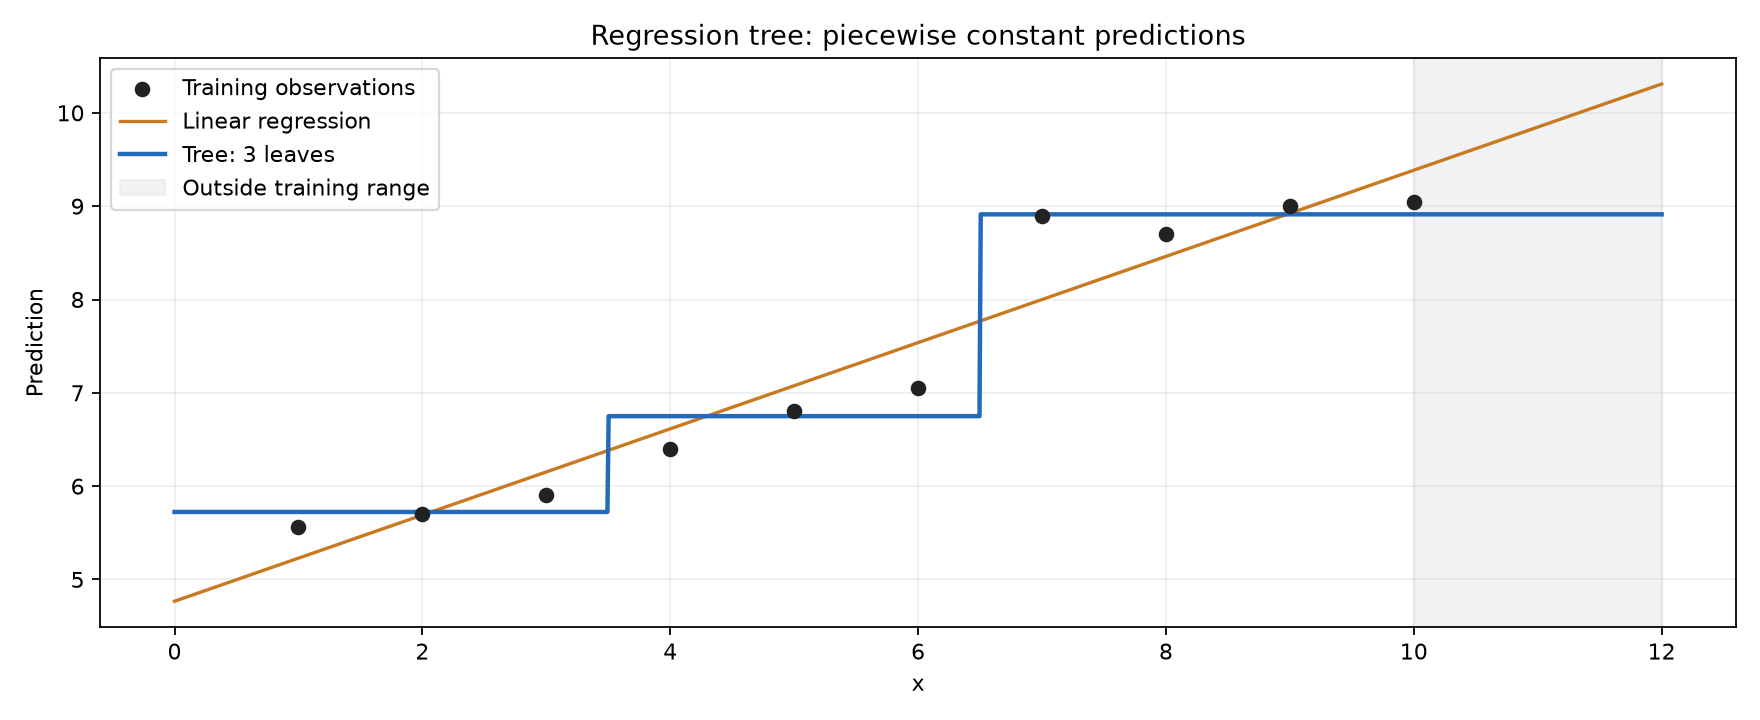

*补充绘图：黑点是训练数据，橙线是线性回归，蓝线是三叶树；灰区超过训练样本的最大 x。*

线性回归用一条直线表达整体趋势，树用分区常数表达局部差异。这里树的**训练**误差更小，不能据此宣布泛化能力更好，因为这 10 个点同时用于训练和计算 MSE。

树预测 `x=12` 时仍输出最后一个叶子的均值 `8.9125`。普通回归树不能像带趋势项的模型那样向训练范围之外延长斜率；如果业务依赖趋势外推，应专门设计验证场景。

让树无限制生长可能把每个点都分成一个叶子，训练误差接近 0，却容易把噪声当规律。

## 13. 剪枝：控制过拟合

深树往往能正确记住训练样本，却把偶然噪声也写成规则。剪枝或生长限制通过减少分支，降低复杂度；是否改善泛化需要训练之外的数据检验。

| 方法 | 何时控制 | 常见方式 | 主要取舍 |
| --- | --- | --- | --- |
| 预剪枝 | 生长过程中 | 限制深度、最小叶子数、划分改进门槛，或按验证表现决定是否继续 | 更省计算，过早停止可能欠拟合 |
| 后剪枝 | 先生成较完整的树，再删子树 | 验证误差剪枝、代价复杂度剪枝 | 能观察更完整结构，需额外训练或评估 |

课程西瓜例子用验证集准确率演示预剪枝与后剪枝；sklearn 的 `ccp_alpha` 使用另一种代价复杂度方法。两种方法不要混为同一实现。

验证集用于选择剪枝强度，测试集用于最终评估。如果对同一个测试集反复尝试多种树再选最高分，测试集就已经被当成验证集使用。

### 13.1 课程西瓜训练集与验证集

课程用 10 条训练样本构建树，用 7 条验证样本检查分裂和剪枝。图中“编号”是原数据编号，不是当前表的连续行号。

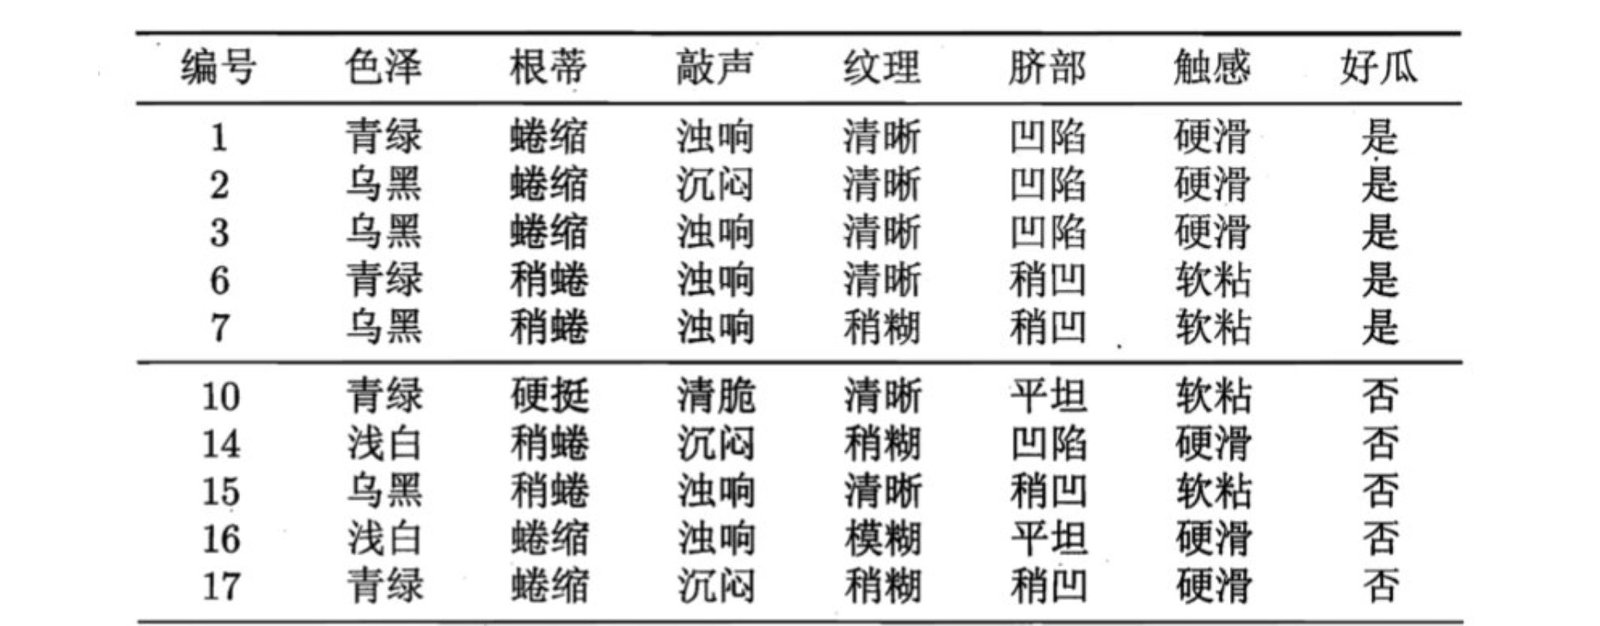

*训练集：决定候选特征、节点的类别和分裂规则。*

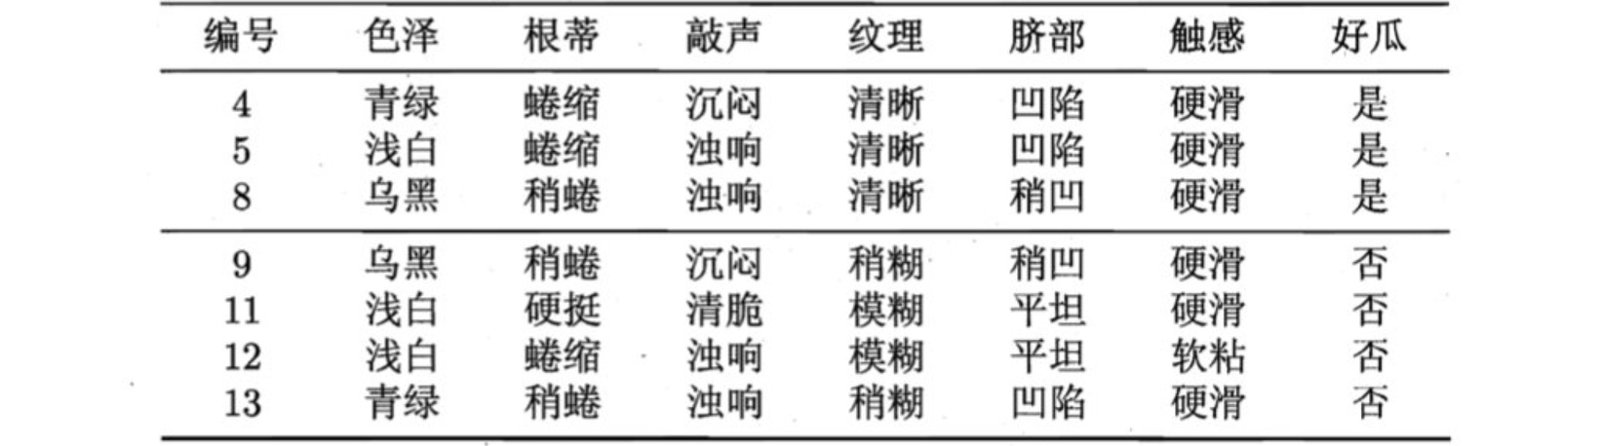

*验证集：比较候选树的预测效果，不用于直接拟合节点规则。这里 7 条样本的准确率每变化一条就变化约 14.3 个百分点，结论容易受个别样本影响。*

以下沿用原课“准确率严格提高才接受操作”的演示规则。准确率并列时是否偏好简单模型，是可以另行设计的选择原则。

### 13.2 完整树和未分裂基线

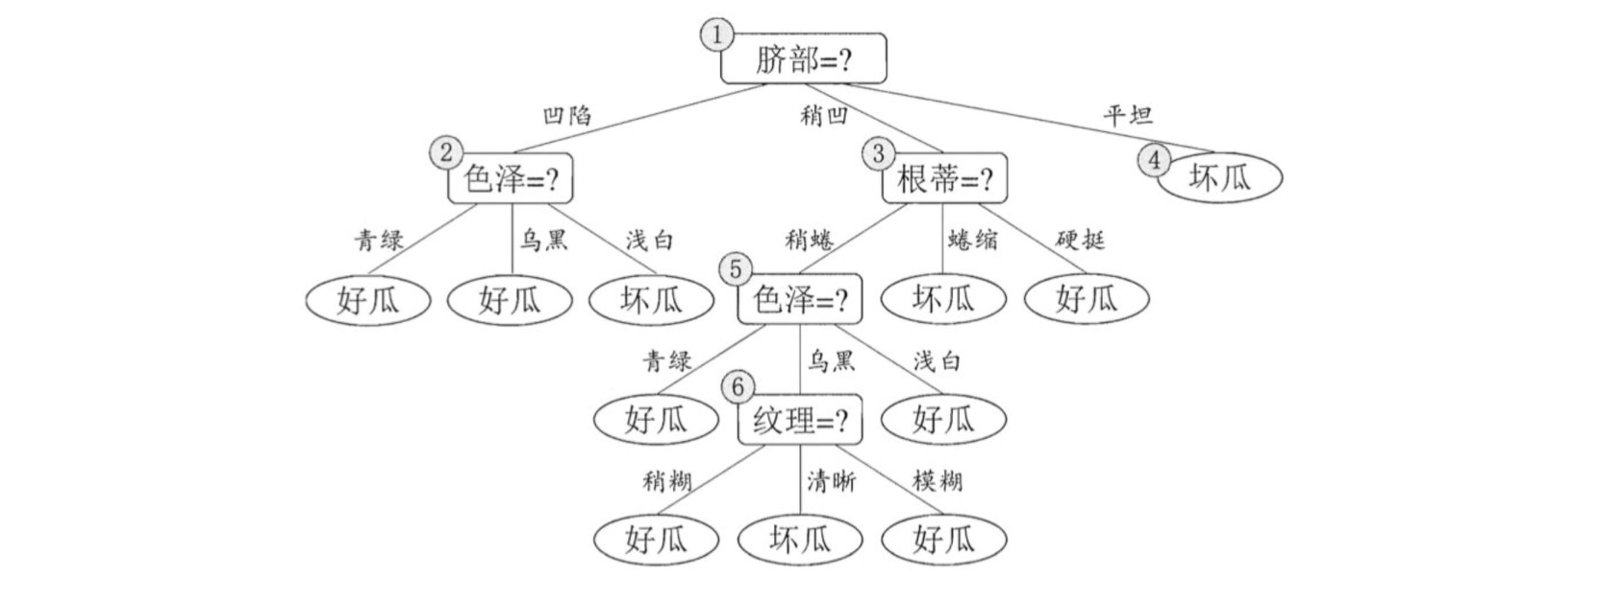

*原课完整树，包含脐部、色泽和根蒂判断。根按离散取值生成 3 个分支，因此这张示意图不是 CART 二叉树。*

初始只有一个根叶子时，课程约定其标签为“好瓜”，在验证集上正确 3 条，准确率 $3/7=42.9\%$。本例训练多数类并列时采用这个约定，不能让验证集决定叶子的标签。

完整生长的树在验证集上也只有 $3/7$，说明复杂结构并未自动带来更好效果。

### 13.3 预剪枝：分裂前先问验证结果

| 操作 | 验证集正确数 | 决定 |
| --- | ---: | --- |
| 保留单根叶子“好瓜” | 3/7 | 基线 |
| 根按脐部分裂 | 5/7 | 接受 |
| 节点 2 继续按色泽分裂 | 4/7 | 拒绝，验证准确率下降 |
| 节点 3 继续按根蒂分裂 | 5/7 | 拒绝，没有严格提高 |
| 节点 4 已经纯净 | — | 不再分裂 |

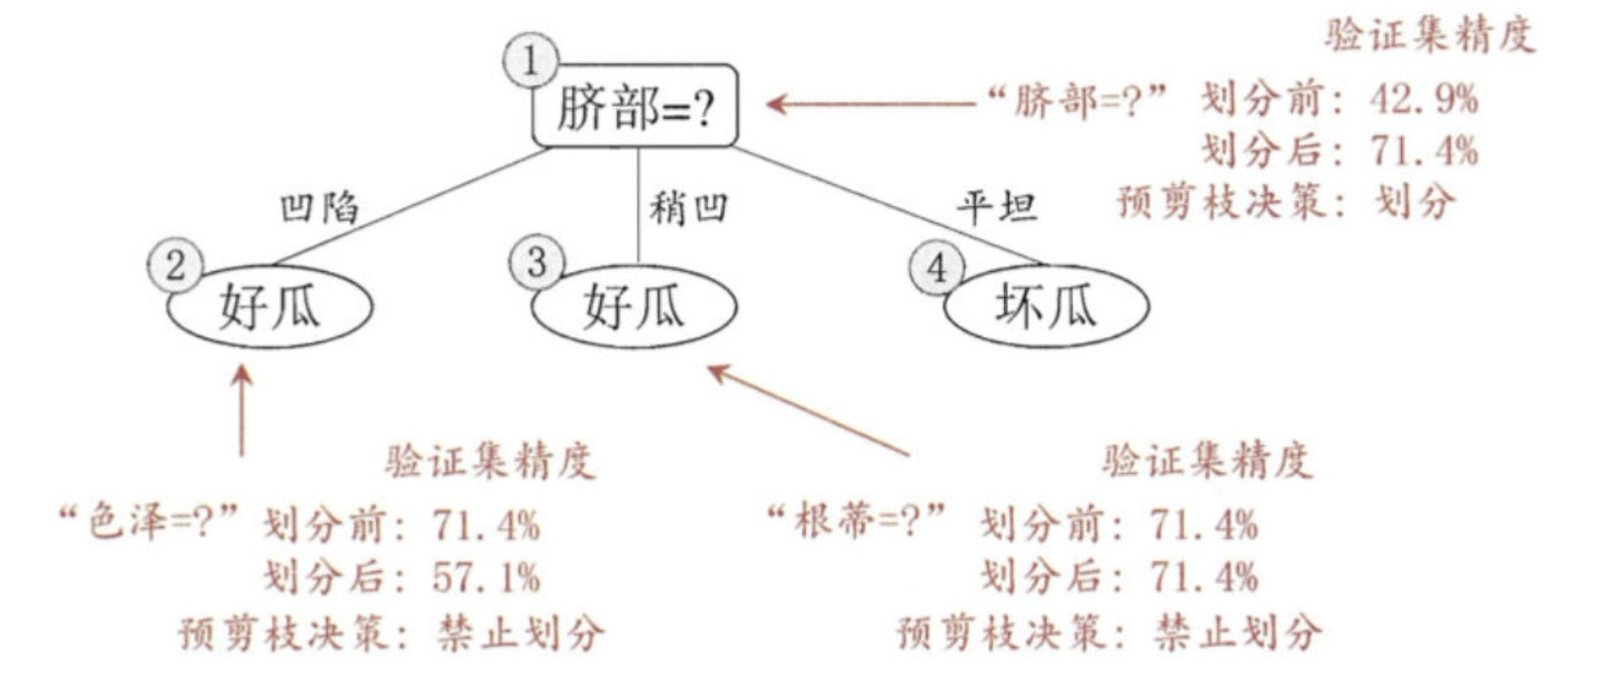

*原课预剪枝结果：根按脐部分裂，子节点保留叶子，验证准确率为 71.4%。*

这种预剪枝依赖当前分裂的即时表现。某个分裂单独看可能没有帮助，但再往下分几层后可能显著改善；过早阻止会错失后续结构。这也是预剪枝欠拟合风险的来源。

### 13.4 后剪枝：先长完整，再自底向上简化

从完整树的 $3/7$ 开始，依次考察内部节点。把子树替换为一个叶子时，标签由该节点训练样本的多数类决定。

| 考察操作 | 剪掉后的验证正确数 | 课程决定 |
| --- | ---: | --- |
| 剪掉节点 6 的子树 | 4/7 | 接受 |
| 再把节点 5 替换为叶子 | 4/7 | 保留，不严格提升 |
| 把节点 2 替换为叶子 | 5/7 | 接受 |
| 把节点 3 替换为叶子 | 5/7 | 保留，不严格提升 |
| 把根节点 1 替换为叶子 | 3/7 | 保留，准确率下降 |

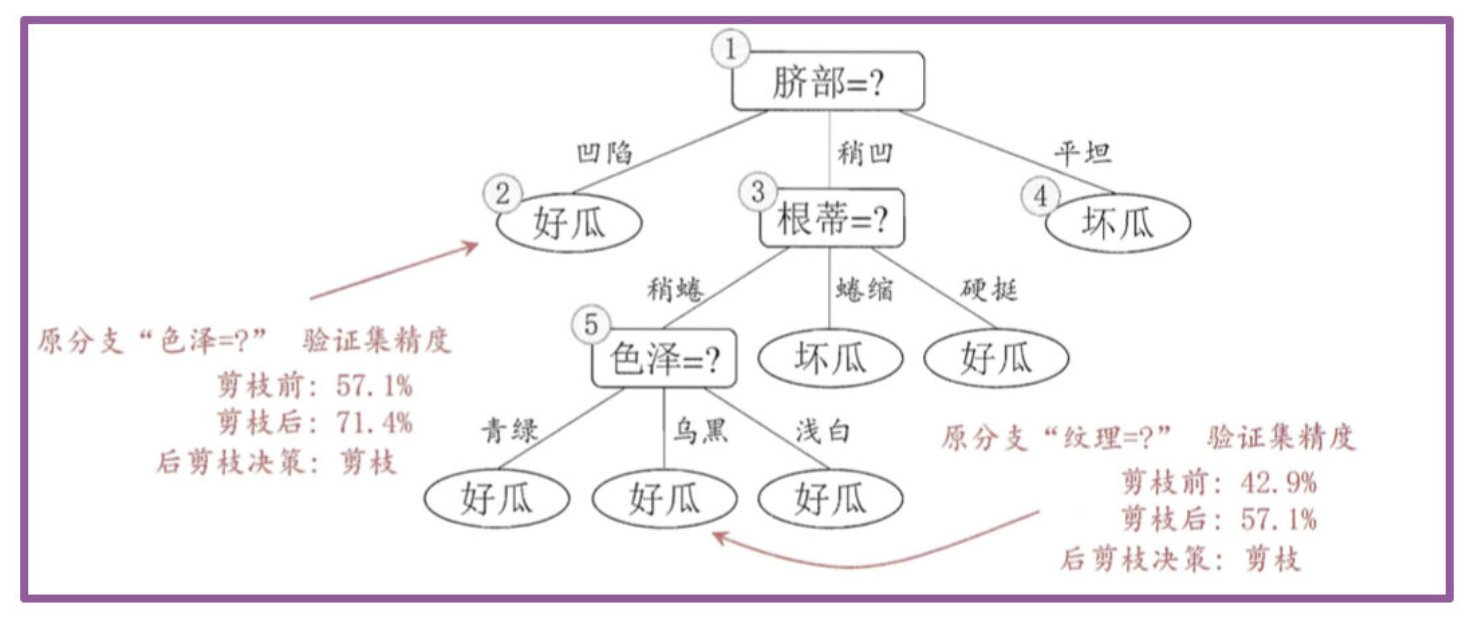

*原课后剪枝过程图，节点号对照完整树。课程最终验证准确率为 5/7，即 71.4%。*

本例预剪枝和后剪枝最终分数相同，但树的结构和路径不同。不能由这一小表推断“后剪枝一定更好”或“更简单一定更准确”。

## 14. sklearn 后剪枝：代价复杂度

代价复杂度剪枝在拟合误差和叶子数量之间折中：

$$R_\alpha(T)=R(T)+\alpha\,|\widetilde T|$$

$R(T)$ 是树叶不纯度的加权和，$|\widetilde T|$ 是叶子数；sklearn 参数 `ccp_alpha` 对应非负 $\alpha$。

- $\alpha$ 小：复杂结构的惩罚小，通常保留更多叶子。
- $\alpha$ 大：需要更大的拟合收益才能保留子树，通常树更简单。
- 在给定训练数据与其他参数下，候选 $\alpha$ 可由 `cost_complexity_pruning_path()` 获得。

该方法按训练数据的不纯度与复杂度生成剪枝路径，不是每剪一个节点就去验证集问一次是否正确更多。验证集的职责是从路径上选择一个候选强度。

下例将数据约按 60%/20%/20% 分成 fit、validation、test。路径只由 fit 生成，验证集选择 alpha，模型固定后再评估 test。

### 14.1 补充实战：乳腺癌内置数据

本例使用 sklearn 内置 `load_breast_cancer()`，属于剪枝流程演示，不是临床决策工具。数据编码 `0=malignant、1=benign`；用 macro-F1 避免误把某个数字自动当成业务正例。

```python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score

data = load_breast_cancer()
X_dev, X_test, y_dev, y_test = train_test_split(
    data.data, data.target, test_size=0.2, stratify=data.target,
    random_state=21)
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=21)

# 剪枝路径只从 fit 集得到，验证集用于选择 alpha
base = DecisionTreeClassifier(random_state=21)
path = base.cost_complexity_pruning_path(X_fit, y_fit)
alphas = np.unique(path.ccp_alphas)
records, models = [], []
for alpha in alphas:
    model = DecisionTreeClassifier(ccp_alpha=float(alpha), random_state=21)
    model.fit(X_fit, y_fit)
    models.append(model)
    records.append({
        "alpha": float(alpha), "leaves": model.get_n_leaves(),
        "fit_accuracy": accuracy_score(y_fit, model.predict(X_fit)),
        "valid_accuracy": accuracy_score(y_valid, model.predict(X_valid)),
    })
scores = pd.DataFrame(records)
# 验证准确率并列时，选叶子更少的树；仍同分时按原顺序
best_index = scores.sort_values(
    ["valid_accuracy", "leaves"], ascending=[False, True],
    kind="stable").index[0]
chosen = models[best_index]

# 固定模型后，测试集只在这里报告一次；本例不重新拟合
test_pred = chosen.predict(X_test)
pruning_result = {
    "fit_size": len(y_fit), "valid_size": len(y_valid), "test_size": len(y_test),
    "best_alpha": float(scores.loc[best_index, "alpha"]),
    "leaves": chosen.get_n_leaves(), "depth": chosen.get_depth(),
    "valid_accuracy": float(scores.loc[best_index, "valid_accuracy"]),
    "test_accuracy": accuracy_score(y_test, test_pred),
    "test_macro_f1": f1_score(y_test, test_pred, average="macro"),
    "unpruned_leaves": int(scores.iloc[0]["leaves"]),
    "unpruned_valid_accuracy": float(scores.iloc[0]["valid_accuracy"]),
}
print(scores.round(6).to_string(index=False))
print(pruning_result)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(scores["alpha"], scores["fit_accuracy"], "o-", label="Fit")
axes[0].plot(scores["alpha"], scores["valid_accuracy"], "s-", label="Validation")
axes[0].set(xlabel="ccp_alpha", ylabel="Accuracy", ylim=(0.5, 1.03))
axes[0].legend()
axes[1].step(scores["alpha"], scores["leaves"], where="post")
axes[1].set(xlabel="ccp_alpha", ylabel="Number of leaves")
for ax in axes:
    ax.set_xscale("symlog", linthresh=0.002)
    ax.set_xlim(left=0)
    ax.set_xlabel("ccp_alpha (symlog scale)")
    ax.axvline(pruning_result["best_alpha"], color="#c87a22", linestyle="--")
    ax.grid(alpha=0.2)
fig.suptitle("Cost-complexity pruning | choose alpha with validation data")
fig.tight_layout()
plt.show()
```

并列时选叶子更少的树。这个选择规则在看测试成绩前确定，不能看过测试分数后反复改并列策略。

本例直接保留已经在 fit 上训练的选中模型，没有重新拟合。实际项目也可在确定参数后使用更多开发数据重训，但要明确记录训练方案；若重新计算路径或继续选参数，仍须留独立验证数据。

### 14.2 本轮剪枝结果

| 指标 | 实际值 |
| --- | --- |
| fit / validation / test 样本数 | 341 / 114 / 114 |
| 选中 ccp_alpha | 0.0048875855 |
| 选中树深度 / 叶子数 | 4 / 7 |
| 验证 accuracy | 0.938596 |
| 最终测试 accuracy | 0.929825 |
| 最终测试 macro-F1 | 0.922973 |

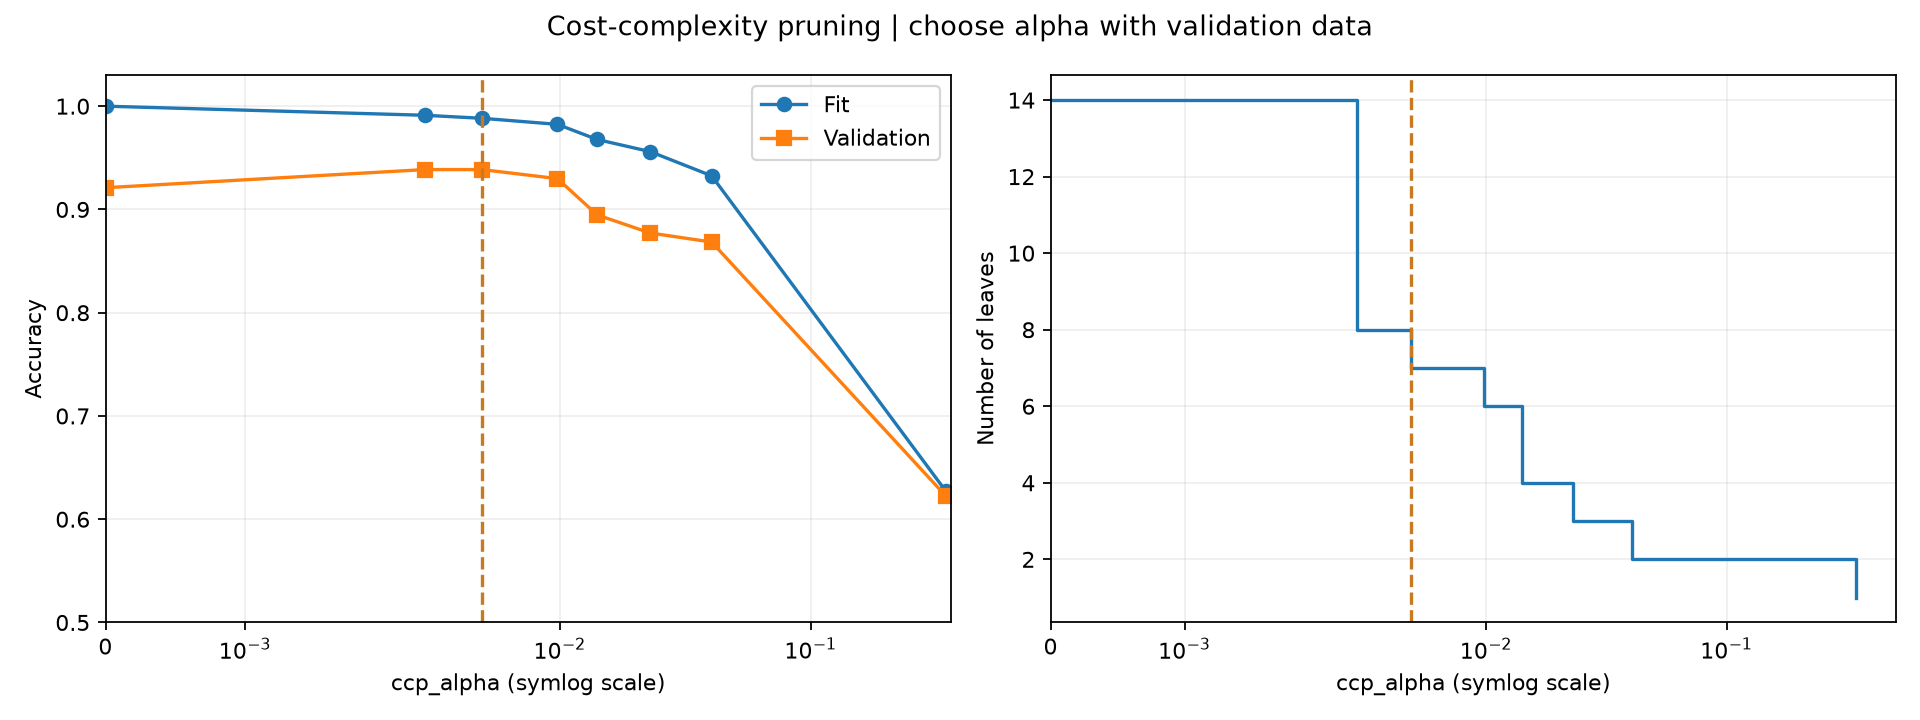

*补充绘图：左图只画 fit 与 validation，右图展示叶子数；虚线是选中的 alpha。横轴采用对称对数刻度，让靠近 0 的几个候选也能看清；测试集分数不参与曲线或参数选择。*

未剪枝的树有 14 个叶子，fit 准确率为 1，但验证准确率约 0.9211。选中树有 7 个叶子，验证准确率约 0.9386。惩罚继续变大时，验证表现下降，最后只剩一个叶子，出现明显欠拟合。

这是一个固定切分上的教学结果。需要稳定估计时应进行合适的交叉验证；数据少时，一个验证分数不能代表所有使用场景。

## 15. 课程作业：手工构建贷款 ID3 树

这是一组独立于 CART 十行表的教学数据。15 条中 9 条“同意”、6 条“拒绝”。不要混用两份表的标签和样本数。

| ID | 年龄 | 有工作 | 有房子 | 信贷情况 | 类别 |
| ---: | --- | --- | --- | --- | --- |
| 1 | 青年 | 否 | 否 | 一般 | 拒绝 |
| 2 | 青年 | 否 | 否 | 好 | 拒绝 |
| 3 | 青年 | 是 | 否 | 好 | 同意 |
| 4 | 青年 | 是 | 是 | 一般 | 同意 |
| 5 | 青年 | 否 | 否 | 一般 | 拒绝 |
| 6 | 中年 | 否 | 否 | 一般 | 拒绝 |
| 7 | 中年 | 否 | 否 | 好 | 拒绝 |
| 8 | 中年 | 是 | 是 | 好 | 同意 |
| 9 | 中年 | 否 | 是 | 非常好 | 同意 |
| 10 | 中年 | 否 | 是 | 非常好 | 同意 |
| 11 | 老年 | 否 | 是 | 非常好 | 同意 |
| 12 | 老年 | 否 | 是 | 好 | 同意 |
| 13 | 老年 | 是 | 否 | 好 | 同意 |
| 14 | 老年 | 是 | 否 | 非常好 | 同意 |
| 15 | 老年 | 否 | 否 | 一般 | 拒绝 |

$$H(D)=-\frac9{15}\log_2\frac9{15}-\frac6{15}\log_2\frac6{15}=0.970951$$

先自己计算四个特征的信息增益，再看下一个单元的代码与答案。

### 15.1 信息增益复算代码

```python
import pandas as pd

# 先运行 entropy、feature_metrics；这是课程教学数据
loan_id3 = pd.DataFrame([
    ["青年", "否", "否", "一般", "拒绝"],
    ["青年", "否", "否", "好", "拒绝"],
    ["青年", "是", "否", "好", "同意"],
    ["青年", "是", "是", "一般", "同意"],
    ["青年", "否", "否", "一般", "拒绝"],
    ["中年", "否", "否", "一般", "拒绝"],
    ["中年", "否", "否", "好", "拒绝"],
    ["中年", "是", "是", "好", "同意"],
    ["中年", "否", "是", "非常好", "同意"],
    ["中年", "否", "是", "非常好", "同意"],
    ["老年", "否", "是", "非常好", "同意"],
    ["老年", "否", "是", "好", "同意"],
    ["老年", "是", "否", "好", "同意"],
    ["老年", "是", "否", "非常好", "同意"],
    ["老年", "否", "否", "一般", "拒绝"],
], columns=["年龄", "有工作", "有房子", "信贷情况", "类别"])
for col in ["年龄", "有工作", "有房子", "信贷情况"]:
    _, gain, _, _ = feature_metrics(
        loan_id3["类别"].tolist(), loan_id3[col].tolist())
    print(col, round(gain, 6))

no_house = loan_id3.loc[loan_id3["有房子"].eq("否")]
_, second_gain, _, _ = feature_metrics(
    no_house["类别"].tolist(), no_house["有工作"].tolist())
print("无房子分支中，有工作的信息增益：", round(second_gain, 6))
pred = loan_id3.apply(
    lambda row: "同意" if row["有房子"] == "是" or row["有工作"] == "是" else "拒绝",
    axis=1)
print("这15条训练样本上的准确率：", pred.eq(loan_id3["类别"]).mean())
```

| 特征 | 根节点信息增益 |
| --- | --- |
| 年龄 | 0.083007 |
| 有工作 | 0.323650 |
| 有房子 | 0.419973 |
| 信贷情况 | 0.362990 |

代码中的最后一行检查训练表是否被规则完全区分，不是独立测试准确率。

### 15.2 参考树与第二层计算

有房子为“是”的 6 条全部同意，直接生成同意叶子。有房子为“否”的 9 条中，3 条同意、6 条拒绝：

$$H(D_{\mathrm{无房}})=H\left(\frac39,\frac69\right)=0.918296$$

在无房子子集中，按有工作分裂：有工作的 3 条全部同意，无工作的 6 条全部拒绝，条件熵为 0，信息增益为 0.918296。因此参考树为：

```text
有房子？
├─ 是 → 同意
└─ 否 → 有工作？
        ├─ 是 → 同意
        └─ 否 → 拒绝
```

从根节点角度，有房子的条件熵为 $\frac6{15}\times0+\frac9{15}\times0.918296=0.550978$，所以增益约 `0.419973`，是四个特征中最大者。

参考树在这 15 条训练数据上全对，只说明它覆盖了教学表。实际贷款决策还需要明确业务规则、数据代表性和验证方式，不能直接部署这棵示意树。

## 16. 易错点对照

| 容易写错的说法或做法 | 正确理解 |
| --- | --- |
| 熵最大就是 1 | 只有二分类均匀分布最大为 1 bit；K 类最大为 $\log_2K$ |
| 把三个子节点熵直接平均 | 按各子节点样本量加权 |
| 原课所有熵值都使用同一底数 | 开头用了自然对数；本篇统一 $\log_2$ |
| 信息增益最高的唯一 ID 一定最好 | 可能只在记住样本，先检查特征意义 |
| 分裂信息计算每个分支的标签比例 | 计算的是各分支大小占父节点的比例 |
| `criterion="entropy"` 等于 C4.5 | sklearn 仍是二叉树，不使用增益率 |
| CART 对婚姻直接分成三叉 | 要搜索类别集合二分；one-hot 的行为另有区别 |
| 收入阈值在全量数据上选好再切训练集 | 切分与模型选择只能使用训练或开发数据 |
| 树不需要标准化，所以不用预处理 | 类别、缺失、目标泄漏仍必须处理 |
| 小叶子会自动和兄弟一起剪掉 | `min_samples_leaf` 在生长阶段拒绝不合法切分 |
| 回归树拟合的是平滑曲线 | 普通回归树是区域内常数、区域间跳变 |
| 左右子树误差直接取算术平均 | 用 SSE 相加或按样本数加权 MSE |
| 训练 MSE 更低就是泛化更好 | 用独立验证或测试数据衡量泛化 |
| 概率为 1 就表示绝对可靠 | 只是叶子内训练类别纯净，需独立评估 |
| 特征重要性表示因果影响 | 它反映模型利用的关联，且可能有偏差 |
| 用测试集选择 alpha 后报告同一最高分 | 使用验证集或交叉验证选参数，测试最后一次 |
| 后剪枝总能提升准确率 | 简化是否有益取决于数据与选择方式 |

## 17. 练习与复习

1. 不看答案，手算六样本 a 的条件熵和增益；再加入唯一 ID，解释增益率为何选择变化。
2. 在论坛表中删除“活跃度”，按性别构建第一层，比较两个子集的标签分布。
3. 自己计算收入阈值 `80`、`97.5` 的加权 Gini，解释为什么 97.5 更好。
4. 把 Iris 的最大深度改为 1，另留验证集观察欠拟合；不要在原测试集上反复选最优深度。
5. 复算回归根阈值 `6.5` 和左子树阈值 `3.5` 的均值与 SSE；检查新样本 `x=4.2`、`x=12` 的输出。
6. 用自己的话说明课程验证准确率剪枝与 sklearn 代价复杂度剪枝的差别。
7. 对贷款表重新手工画 ID3 树，并解释为什么训练 100% 不等于未知样本 100%。

应能口头说明：节点判断特征，分支划分样本，叶子输出预测；ID3 看熵降低，C4.5 在增益上考虑分支分散程度，CART 每次二分；平方误差回归叶子取均值；通过复杂度限制和验证数据选择树的大小。

## 18. 资料与本篇验证范围

原课依据：`06_决策树/02-笔记/决策树.md`，以及本 Notebook 内嵌的 12 张课程配图。没有取得 `day06.zip`，没有读取其 CSV 或声称运行其代码；也没有转录课程视频。

补充内容：训练集内预处理 Pipeline、Iris 分类完整代码、十点回归精确复算与对比图、内置乳腺癌数据代价复杂度剪枝。新增 3 张图同样内嵌到 Notebook。

本轮验证使用 sklearn 1.9.1、NumPy 2.5.4、pandas 3.0.6。熵、论坛信息增益、C4.5 增益率、CART 阈值、回归 SSE 与贷款作业均已复算；Titanic 管道用合成数据检查结构，未计算课程 CSV 的真实成绩。

可进一步查阅：[sklearn 决策树用户指南](https://scikit-learn.org/stable/modules/tree.html)、[DecisionTreeClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html)、[DecisionTreeRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html)、[代价复杂度剪枝示例](https://scikit-learn.org/stable/auto_examples/tree/plot_cost_complexity_pruning.html)。安装版本不同，参数支持和绘图显示以对应版本为准。